# 07 - Robustness to noise

**Owner:** Luiz Susin - CSC 7333 Group 6

Real-world images are rarely as clear as the FERPlus test images, and cheap or poor-quality cameras can introduce noise. People also cover their eyes (for example with sunglasses) and/or mouth (for example with a face mask) and often there is poor lighting. This notebook analyzes the robustness of the four trained models to different corruptions. No retraining is undertaken, and all models see identically corrupted versions of the test data.

Three types of corruption are analyzed at five increasing severities:

| Corruption | What it simulates | Levels 1-5 |
|---|---|---|
| Gaussian noise | sensor noise of dark or cheap cameras | noise std of 4, 8, 16, 24, 32 gray levels |
| Occlusion | a hand, an object or hair covering part of the face | black square of 8, 12, 16, 20, 24 px (of 48) at a random position |
| Low light | an under-exposed photo | pixel values multiplied by 0.6, 0.4, 0.25, 0.15, 0.08 |

Furthermore, we occlude two bands of the face with the same area, the eyes (as if wearing sunglasses) and the mouth (as if wearing a face mask), to assess which facial area each model relies on most.

The corruptions are introduced to the 48×48 image (native image size for FER2013). For ResNet-18 and EfficientNet-B0, the corrupted image is then upsampled to 224×224 using bicubic interpolation. This is precisely how the training data arrays were generated (on clean images, it matches the provided 224×224 files up to a one gray level rounding difference in a few pixels). Severities were chosen on the validation data. Level 5 is quite severe, but it does not drive every model down to chance level.

The analysis is conducted locally on a computer's CPU and takes around 45 minutes. It can be considerably quicker if a GPU is used. The four trained models should be in the `models/` directory.

In [1]:
import json
import os
import time
from pathlib import Path

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from joblib import Parallel, delayed
from skimage.feature import hog
from sklearn.metrics import f1_score
from torch import nn
from torchvision import models

# Folders can be accessed whether the notebook is opened from the root of the repository or from notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"
FIG = RESULTS_DIR / "figures"
TABLES = RESULTS_DIR / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
CSV = RESULTS_DIR / "robustness.csv"

CLASSES = ["Neutral", "Happiness", "Surprise", "Sadness", "Anger", "Fear"]
SEED = 42
PRETTY_NAMES = {"hog_svm": "HOG + SVM", "cnn_scratch": "CNN (scratch)", "resnet18": "ResNet-18",
                "efficientnet_b0": "EfficientNet-B0"}
sns.set_theme(style="whitegrid")
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(os.cpu_count())

In [2]:
def load_split(split, size=48):
    # Images and classes for one split. Excludes Disgust and Contempt. As the 224x224 training data exceeds 1 GB,
    # memory mapping is used. Only the selected images are then copied.
    names = np.load(DATA_DIR / f"FER2013{split}_labels.npy")
    images = np.load(DATA_DIR / f"FER2013{split}_{size}_images.npy", mmap_mode="r")
    keep = np.isin(names, CLASSES)
    labels = np.array([CLASSES.index(name) for name in names[keep]])
    return np.ascontiguousarray(images[keep]), labels


def hog_features(images, cell_size, orientations, block_size=2):
    # Each image generates one HOG vector. This is done in parallel on all CPU cores.
    vectors = Parallel(n_jobs=-1, batch_size=500)(
        delayed(hog)(image, orientations=orientations, pixels_per_cell=(cell_size, cell_size),
                     cells_per_block=(block_size, block_size), block_norm="L2-Hys")
        for image in images)
    return np.array(vectors, dtype=np.float32)


class ScratchCNN(nn.Module):
    # A VGG-type network for 48x48 grayscale faces. Each of the four sections halves the image size (48, 24, 12, 6,
    # 3) and doubles the number of filters. Global average pooling followed by a compact fully-connected section
    # produces the 6 class scores.
    def __init__(self, base_filters=64, dropout=0.4, block_dropout=0.25):
        super().__init__()
        blocks, in_ch = [], 1
        for out_ch in [base_filters, base_filters * 2, base_filters * 4, base_filters * 8]:
            blocks.append(nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
                nn.MaxPool2d(2), nn.Dropout(block_dropout)))
            in_ch = out_ch
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(in_ch, 256), nn.ReLU(inplace=True),
                                        nn.Dropout(dropout), nn.Linear(256, len(CLASSES)))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


def load_network(name):
    # Restore a network from the checkpoints of notebooks 03 to 05.
    checkpoint = torch.load(MODELS_DIR / f"{name}.pt", map_location="cpu")
    if name == "cnn_scratch":
        model = ScratchCNN(**checkpoint["model_kwargs"])
    elif name == "resnet18":
        model = models.resnet18()
        model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, len(CLASSES)))
    else:
        model = models.efficientnet_b0()
        model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, len(CLASSES)))
    model.load_state_dict(checkpoint["state_dict"])
    return model.eval()


def to_tensor(images, pretrained):
    # Convert the uint8 faces with shape (N, H, W) to the normalized float batch used to train the networks. For
    # the ImageNet networks, the gray channel is repeated 3 times and scaled using the ImageNet mean and standard
    # deviation.
    x = torch.from_numpy(images).unsqueeze(1).float() * (1 / 255)
    if not pretrained:
        return (x - 0.5) / 0.5
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    return (x.repeat(1, 3, 1, 1) - mean) / std


def predict(name, images):
    # Output classes of one model for a batch of 48x48 uint8 faces.
    if name == "hog_svm":
        return svm["pipeline"].predict(hog_features(images, **svm["hog_params"]))
    pretrained = name != "cnn_scratch"
    preds = []
    with torch.inference_mode():
        for start in range(0, len(images), 256):
            batch = images[start:start + 256]
            if pretrained:
                # Same bicubic upsampling as was used to convert the 48x48 faces to the 224x224 training data.
                batch = np.stack([cv2.resize(image, (224, 224), interpolation=cv2.INTER_CUBIC) for image in batch])
            preds.append(networks[name](to_tensor(batch, pretrained).to(device)).argmax(1).cpu().numpy())
    return np.concatenate(preds)


svm = joblib.load(MODELS_DIR / "hog_svm.joblib")
# Using channels-last data format allows quicker convolution operations on the CPU.
networks = {name: load_network(name).to(device, memory_format=torch.channels_last)
            for name in ["cnn_scratch", "resnet18", "efficientnet_b0"]}
MODEL_NAMES = ["hog_svm", *networks]
print("device:", device, "| models:", [PRETTY_NAMES[m] for m in MODEL_NAMES])

x_test, y_test = load_split("Test")
print("test images:", x_test.shape)

device: cpu | models: ['HOG + SVM', 'CNN (scratch)', 'ResNet-18', 'EfficientNet-B0']
test images: (3103, 48, 48)


## 1. What the corruptions look like

One test face is shown at each severity. The randomly generated occlusion is in a different area for each image.

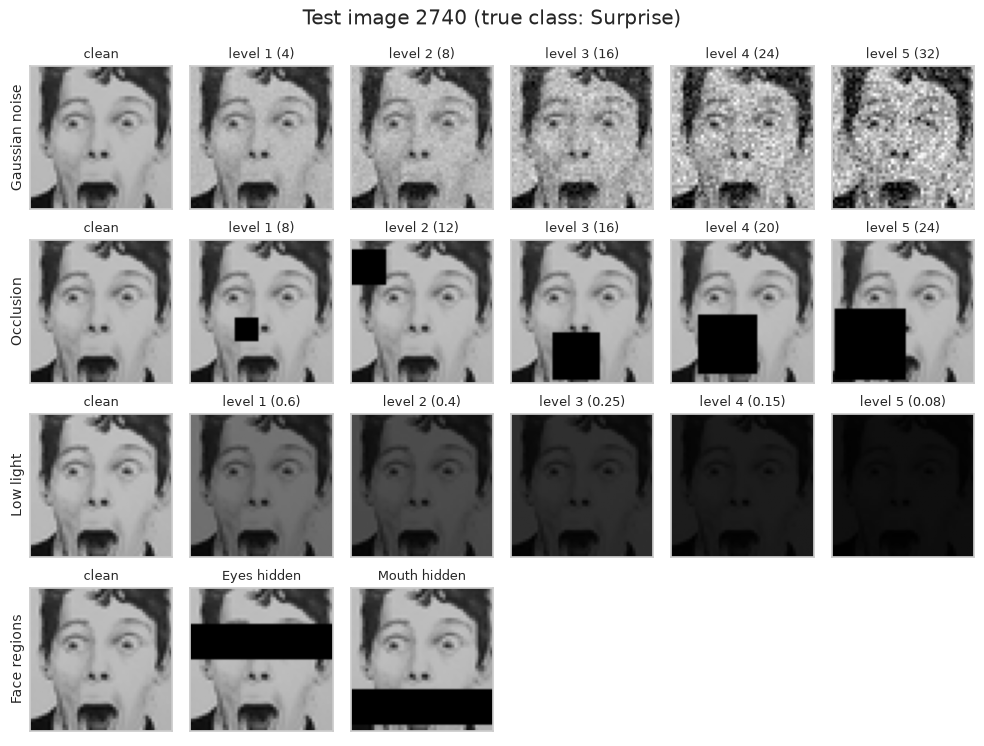

In [3]:
# There are 5 degrees of corruption, from slight (1) to heavy (5). These were chosen using the validation data.
# Although level 5 is a heavy corruption, it does not cause all models to fall to chance performance.
SEVERITIES = {
    "gaussian_noise": [4, 8, 16, 24, 32],
    "occlusion": [8, 12, 16, 20, 24],
    "low_light": [0.6, 0.4, 0.25, 0.15, 0.08],
}
CORRUPTION_NAMES = {"gaussian_noise": "Gaussian noise", "occlusion": "Occlusion", "low_light": "Low light"}
SEVERITY_LABELS = {"gaussian_noise": "noise std (gray levels)", "occlusion": "patch side (px of 48)",
                   "low_light": "brightness factor"}
# Rows of the 48x48 face that are occluded. For the mean face, the eyes are in rows 12-23 and the mouth in rows
# 34-45. Both of these have equal areas (25% of the image).
REGIONS = {"eyes": (12, 24), "mouth": (34, 46)}
REGION_NAMES = {"eyes": "Eyes hidden", "mouth": "Mouth hidden"}


def corrupt(images, kind, level):
    # Corrupt a batch of uint8 faces at level 1-5 (level 0 returns the uncorrupted faces). The random numbers are
    # solely dependent on the type and degree of corruption and so all models see identical images.
    if level == 0:
        return images.copy()
    severity = SEVERITIES[kind][level - 1]
    rng = np.random.default_rng([SEED, list(SEVERITIES).index(kind), level])
    if kind == "gaussian_noise":
        noisy = images.astype(np.float32) + rng.normal(0, severity, images.shape).astype(np.float32)
        return np.clip(np.rint(noisy), 0, 255).astype(np.uint8)
    if kind == "occlusion":
        out = images.copy()
        ys, xs = rng.integers(0, 49 - severity, (2, len(images)))
        for image, y, x in zip(out, ys, xs):
            image[y:y + severity, x:x + severity] = 0
        return out
    # Low light: reducing the intensity of all pixels reduces both the brightness and contrast.
    return np.rint(images.astype(np.float32) * severity).astype(np.uint8)


def occlude_region(images, region):
    # Cover either the eye region (as with sunglasses) or mouth region (as with a face mask) of the face.
    top, bottom = REGIONS[region]
    out = images.copy()
    out[..., top:bottom, :] = 0
    return out


example = 2740  # a frontal Surprise face that is not duplicated in the training set
kinds = list(SEVERITIES)
fig, axes = plt.subplots(len(kinds) + 1, 6, figsize=(10, 7.6))
for i, kind in enumerate(kinds):
    for level in range(6):
        ax = axes[i, level]
        ax.imshow(corrupt(x_test, kind, level)[example], cmap="gray", vmin=0, vmax=255)
        ax.set_title("clean" if level == 0 else f"level {level} ({SEVERITIES[kind][level - 1]:g})", fontsize=9)
    axes[i, 0].set_ylabel(CORRUPTION_NAMES[kind], fontsize=10)

regions = {"clean": x_test[example], **{REGION_NAMES[r]: occlude_region(x_test[example], r) for r in REGIONS}}
for j, (title, image) in enumerate(regions.items()):
    axes[-1, j].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[-1, j].set_title(title, fontsize=9)
axes[-1, 0].set_ylabel("Face regions", fontsize=10)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
for ax in axes[-1, len(regions):]:
    ax.axis("off")
fig.suptitle(f"Test image {example} (true class: {CLASSES[y_test[example]]})")
fig.tight_layout()
fig.savefig(FIG / "robustness_examples.png", dpi=150)
plt.show()

## 2. Evaluate every model on every corrupted test set

Each corrupted test data set is generated once and shared between all models. Thus, models analyze the same images. As the random numbers only depend on the type and severity of corruption, the same corrupted images are produced each time. Results are saved to `results/robustness.csv`. To re-run the analysis, set `RECOMPUTE = True` (this will also take around 45 minutes on a 22-core CPU).

In [4]:
RECOMPUTE = False


def corrupted_test_sets():
    # The uncorrupted test data, all corruptions at all levels and the two occluded face areas.
    yield "clean", 0, np.nan, x_test
    for kind, severities in SEVERITIES.items():
        for level, severity in enumerate(severities, start=1):
            yield kind, level, severity, corrupt(x_test, kind, level)
    for region in REGIONS:
        yield f"{region}_hidden", 1, np.nan, occlude_region(x_test, region)


if CSV.exists() and not RECOMPUTE:
    robustness = pd.read_csv(CSV)
    print(f"loaded {CSV.name} ({len(robustness)} rows); set RECOMPUTE = True to evaluate again")
else:
    rows, start = [], time.time()
    for kind, level, severity, images in corrupted_test_sets():
        for name in MODEL_NAMES:
            pred = predict(name, images)
            f1 = f1_score(y_test, pred, labels=range(len(CLASSES)), average=None, zero_division=0)
            share = np.bincount(pred, minlength=len(CLASSES)) / len(pred)
            rows.append({"model": name, "corruption": kind, "level": level, "severity": severity,
                         "accuracy": (pred == y_test).mean(), "macro_f1": f1.mean(),
                         **{f"f1_{c}": v for c, v in zip(CLASSES, f1)},
                         **{f"predicted_{c}": s for c, s in zip(CLASSES, share)}})
        scores = "  ".join(f"{PRETTY_NAMES[r['model']]} {r['macro_f1']:.3f}" for r in rows[-len(MODEL_NAMES):])
        print(f"{kind:>15} level {level}: {scores}  ({(time.time() - start) / 60:.1f} min)")
    robustness = pd.DataFrame(rows)
    robustness.to_csv(CSV, index=False, float_format="%.4f")
    print("saved", CSV)

          clean level 0: HOG + SVM 0.631  CNN (scratch) 0.790  ResNet-18 0.831  EfficientNet-B0 0.808  (2.8 min)


 gaussian_noise level 1: HOG + SVM 0.627  CNN (scratch) 0.785  ResNet-18 0.810  EfficientNet-B0 0.778  (5.3 min)


 gaussian_noise level 2: HOG + SVM 0.570  CNN (scratch) 0.746  ResNet-18 0.718  EfficientNet-B0 0.724  (7.6 min)


 gaussian_noise level 3: HOG + SVM 0.404  CNN (scratch) 0.511  ResNet-18 0.505  EfficientNet-B0 0.557  (10.0 min)


 gaussian_noise level 4: HOG + SVM 0.299  CNN (scratch) 0.324  ResNet-18 0.340  EfficientNet-B0 0.390  (12.1 min)


 gaussian_noise level 5: HOG + SVM 0.237  CNN (scratch) 0.174  ResNet-18 0.225  EfficientNet-B0 0.251  (14.8 min)


... (8 outputs left out)

      low_light level 4: HOG + SVM 0.627  CNN (scratch) 0.457  ResNet-18 0.676  EfficientNet-B0 0.625  (35.9 min)


      low_light level 5: HOG + SVM 0.595  CNN (scratch) 0.145  ResNet-18 0.380  EfficientNet-B0 0.394  (38.3 min)


    eyes_hidden level 1: HOG + SVM 0.295  CNN (scratch) 0.564  ResNet-18 0.594  EfficientNet-B0 0.625  (40.6 min)


   mouth_hidden level 1: HOG + SVM 0.226  CNN (scratch) 0.582  ResNet-18 0.650  EfficientNet-B0 0.557  (42.8 min)
saved /home/luizsusin/ferplus-project/results/robustness.csv


As a sanity check, this notebook should replicate the results from notebooks 02-05 for the clean test data.

In [5]:
official = {m: json.loads((RESULTS_DIR / "metrics" / f"{m}.json").read_text())["test"]["macro_f1"]
            for m in MODEL_NAMES}
clean = robustness[robustness.corruption == "clean"].set_index("model")["macro_f1"]
check = pd.DataFrame({"notebooks 02-05": official, "this notebook": clean})
check["difference"] = check["this notebook"] - check["notebooks 02-05"]
check.rename(index=PRETTY_NAMES).round(4)

,notebooks 02-05,this notebook,difference
HOG + SVM,0.6313,0.6313,0.0
CNN (scratch),0.7904,0.7904,0.0
ResNet-18,0.8312,0.8312,0.0
EfficientNet-B0,0.8075,0.8075,0.0


## 3. Macro F1 as the corruption gets stronger

The dotted line shows the macro F1 score achieved by a model which always outputs Neutral, which is where a model ends up when it collapses to a single class.

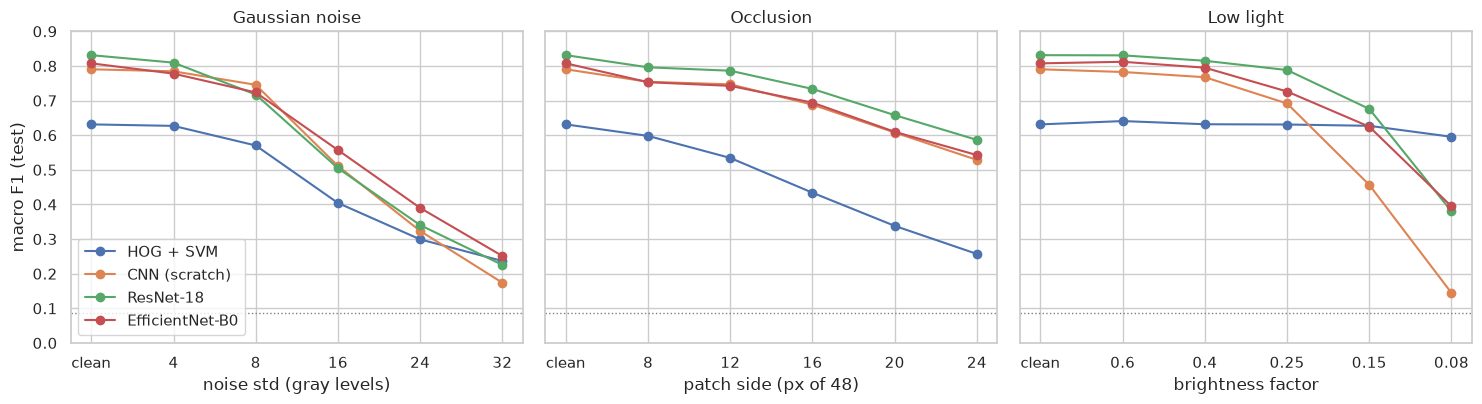

In [6]:
# Macro F1 of a model which always outputs Neutral.
one_class = f1_score(y_test, np.zeros_like(y_test), labels=range(len(CLASSES)), average="macro", zero_division=0)
fig, axes = plt.subplots(1, len(kinds), figsize=(15, 4.2), sharey=True)
for ax, kind in zip(axes, kinds):
    for name in MODEL_NAMES:
        sub = robustness[(robustness.model == name) & (robustness.corruption == kind)].sort_values("level")
        ax.plot([0, *sub.level], [clean[name], *sub.macro_f1], marker="o", label=PRETTY_NAMES[name])
    ax.axhline(one_class, color="gray", linestyle=":", linewidth=1)
    ax.set_xticks(range(6), ["clean", *[f"{s:g}" for s in SEVERITIES[kind]]])
    ax.set_xlabel(SEVERITY_LABELS[kind])
    ax.set_title(CORRUPTION_NAMES[kind])
axes[0].set_ylabel("macro F1 (test)")
axes[0].set_ylim(0, 0.9)
axes[0].legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG / "robustness_curves.png", dpi=150)
plt.show()

## 4. Summary table

Mean macro F1 over the five severities of each corruption. In brackets is the proportion of the original (clean) macro F1 which is retained. The final two columns (the hidden face regions) are single conditions.

In [ ]:
SHORT = {"clean": "Clean", "gaussian_noise": "Noise", "occlusion": "Occlusion", "low_light": "Low light",
         "eyes_hidden": "Eyes hidden", "mouth_hidden": "Mouth hidden"}
corrupted = robustness[robustness.corruption != "clean"]
mean_f1 = corrupted.groupby(["model", "corruption"]).macro_f1.mean().unstack()
summary = pd.concat([clean.rename("clean"), mean_f1], axis=1).loc[MODEL_NAMES, list(SHORT)]
retained = summary.div(summary["clean"], axis=0)


# AI-Generated - This helps generating the LaTeX tables to be used in the written work
def write_latex_table(path):
    # Present the summary in a LaTeX table. The best value in each column is in bold, and the proportion of the
    # clean macro F1 that each model preserves is in parentheses.
    lines = [r"\begin{tabular}{l" + "c" * len(SHORT) + "}", r"\toprule",
             " & ".join(["Model", *SHORT.values()]) + r" \\", r"\midrule"]
    for name in summary.index:
        cells = [PRETTY_NAMES[name]]
        for col in SHORT:
            value = summary.loc[name, col]
            text = rf"\textbf{{{value:.3f}}}" if value == summary[col].max() else f"{value:.3f}"
            if col != "clean":
                text += rf" ({100 * retained.loc[name, col]:.0f}\%)"
            cells.append(text)
        lines.append(" & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    path.write_text("\n".join(lines) + "\n")


write_latex_table(TABLES / "robustness.tex")

table = summary.copy().astype(object)
table["clean"] = summary["clean"].map("{:.3f}".format)
for col in list(SHORT)[1:]:
    table[col] = [f"{v:.3f} ({r:.0%})" for v, r in zip(summary[col], retained[col])]
table.rename(index=PRETTY_NAMES, columns=SHORT)

,Clean,Noise,Occlusion,Low light,Eyes hidden,Mouth hidden
model,,,,,,
HOG + SVM,0.631,0.428 (68%),0.432 (68%),0.625 (99%),0.295 (47%),0.226 (36%)
CNN (scratch),0.790,0.508 (64%),0.665 (84%),0.569 (72%),0.564 (71%),0.582 (74%)
ResNet-18,0.831,0.520 (63%),0.712 (86%),0.698 (84%),0.594 (71%),0.650 (78%)
EfficientNet-B0,0.808,0.540 (67%),0.668 (83%),0.670 (83%),0.625 (77%),0.557 (69%)


## 5. Which classes suffer most?

Variation in F1 relative to the clean test data. Analysis is for severity 3 of each corruption and for each occlusion type.

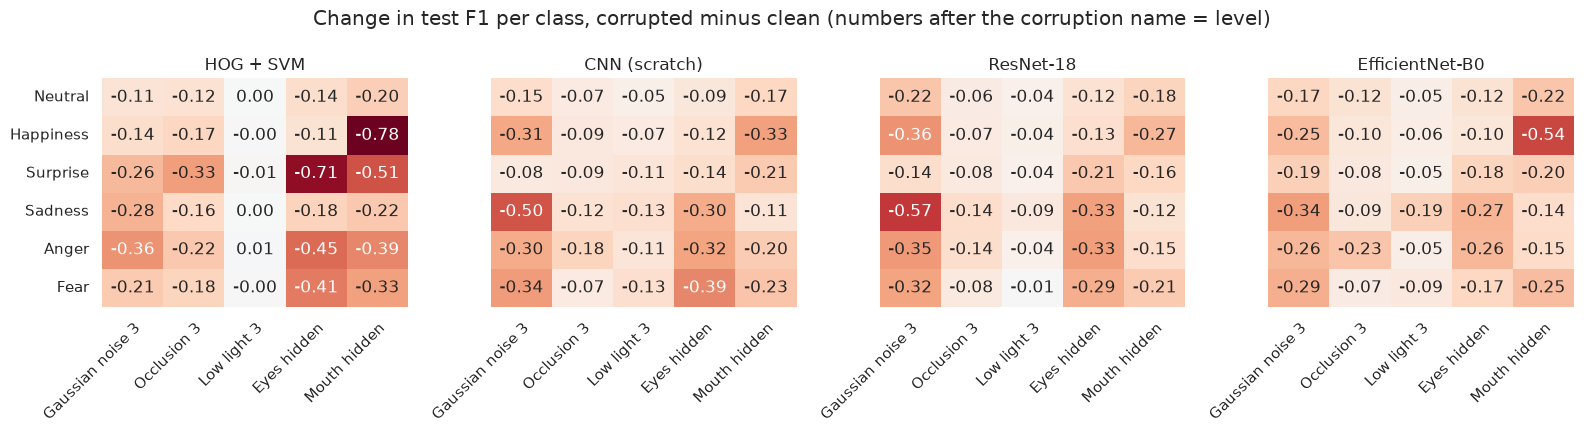

In [8]:
f1_cols = [f"f1_{c}" for c in CLASSES]
conditions = {f"{CORRUPTION_NAMES[k]} 3": (k, 3) for k in kinds}
conditions.update({REGION_NAMES[r]: (f"{r}_hidden", 1) for r in REGIONS})


def class_f1(name, corruption, level):
    row = robustness[(robustness.model == name) & (robustness.corruption == corruption) & (robustness.level == level)]
    return row[f1_cols].iloc[0].to_numpy()


fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(4 * len(MODEL_NAMES), 4.4), sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    base = class_f1(name, "clean", 0)
    change = pd.DataFrame({label: class_f1(name, *cond) - base for label, cond in conditions.items()},
                          index=CLASSES)
    sns.heatmap(change, annot=True, fmt=".2f", cmap="RdBu", vmin=-0.8, vmax=0.8, center=0, cbar=False, ax=ax)
    ax.set_title(PRETTY_NAMES[name])
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
fig.suptitle("Change in test F1 per class, corrupted minus clean (numbers after the corruption name = level)")
fig.tight_layout()
fig.savefig(FIG / "robustness_per_class.png", dpi=150)
plt.show()

## 6. What do the models predict when they fail?

Proportion of test images predicted as Neutral. The dashed line shows the actual proportion of Neutral images within the test data (35%). If a model's results remain close to this line then it continues to spread its predictions over all classes. Should a model's results move up toward 100%, it has fallen back on predicting Neutral.

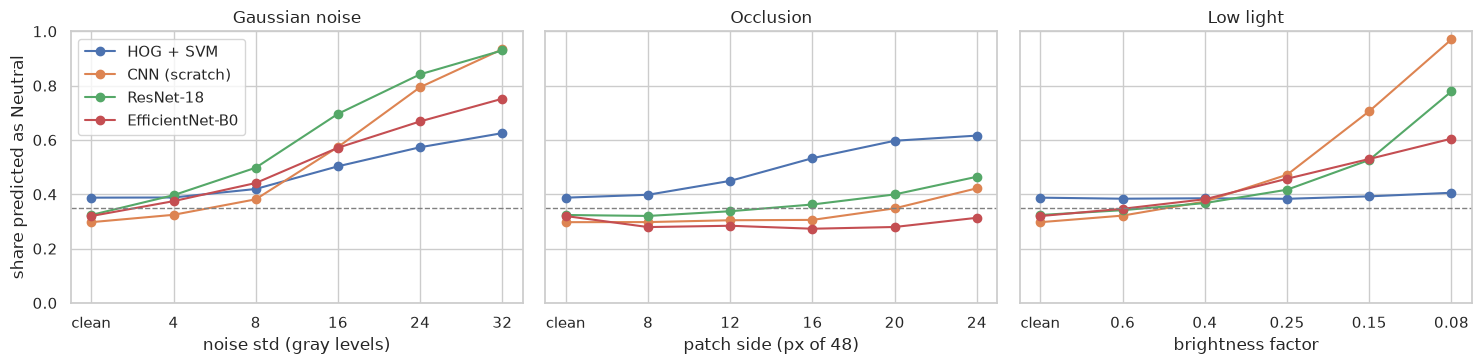

In [9]:
true_neutral = np.mean(y_test == CLASSES.index("Neutral"))
fig, axes = plt.subplots(1, len(kinds), figsize=(15, 3.8), sharey=True)
for ax, kind in zip(axes, kinds):
    for name in MODEL_NAMES:
        sub = robustness[(robustness.model == name) & (robustness.corruption.isin(["clean", kind]))].sort_values("level")
        ax.plot(sub.level, sub.predicted_Neutral, marker="o", label=PRETTY_NAMES[name])
    ax.axhline(true_neutral, color="gray", linestyle="--", linewidth=1)
    ax.set_xticks(range(6), ["clean", *[f"{s:g}" for s in SEVERITIES[kind]]])
    ax.set_xlabel(SEVERITY_LABELS[kind])
    ax.set_title(CORRUPTION_NAMES[kind])
axes[0].set_ylabel("share predicted as Neutral")
axes[0].set_ylim(0, 1)
axes[0].legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "robustness_neutral_share.png", dpi=150)
plt.show()

predicted_cols = [f"predicted_{c}" for c in CLASSES]
heavy = robustness[((robustness.corruption == "gaussian_noise") & (robustness.level.isin([3, 5])))
                   | ((robustness.corruption == "low_light") & (robustness.level == 5))]
(heavy.assign(model=heavy.model.map(PRETTY_NAMES)).set_index(["corruption", "level", "model"])[predicted_cols]
 .rename(columns=lambda c: c.removeprefix("predicted_")).style.format("{:.0%}"))

## 7. Takeaways

- **Gaussian noise is the hardest corruption for every model.** Mild noise (std 4) has at most a 0.03 negative effect on macro F1. However, from std 16 all models lose a large part of their score, although on average they retain a broadly equivalent proportion of their original macro F1 (63–68%). At std 32, HOG+SVM even outperforms both the scratch CNN and ResNet-18. Compared to the scratch CNN, the pretrained models are more adversely affected by mild noise. At std 8, the scratch CNN is the best model.
- **Occlusion is where the networks shine.** They retain 83–86% of their original macro F1, compared to 68% for HOG+SVM, which extracts its features from a fixed grid of cells. ResNet-18 is the most robust model.
- **Low light is the opposite.** Thanks to the block normalization of HOG, HOG+SVM is barely affected by low light. However, all the networks rapidly deteriorate in performance when the brightness of an image falls below 25% and the scratch CNN is particularly badly affected. The networks normalize their input with fixed constants and were only exposed to brightness variations of ±20% during training.
- **When they fail, the networks fall back on Neutral.** The scratch CNN and ResNet-18 both predict Neutral for 93% of images at std 32. The scratch CNN does so for 97% of images at 8% brightness. As the features associated with Sadness are nuanced, this is the first class to be lost.
- **Face regions:** Occluding the eyes or mouth has the greatest detrimental effect on HOG+SVM. EfficientNet-B0 and ResNet-18 place greater importance on the mouth and eyes respectively, in line with their Grad-CAM maps. Occluding the mouth especially negatively affects Happiness and occluding the eyes especially negatively affects Anger and Sadness.
- **Next step:** None of the models was trained using noise or occlusion. Were these corruptions to be used as additional training data (augmentation) and/or the brightness of each image were normalized, it is likely that most of these models' shortcomings could be addressed.